# Customer Lifetime Value: Cohorts, Probabilistic Models, ML

**What you'll learn**

- How to define LTV so it can survive a finance review: contribution margin vs revenue,
  discounting, horizon, and where CAC does and does not enter (payback, LTV:CAC, budget
  allocation).
- Empirical cohort LTV from a transaction log: cumulative-margin curves, extrapolating
  young cohorts, and two ways extrapolation quietly fails (functional-form sensitivity and
  channel mix shift) — quantified against simulated ground truth.
- The shifted-Beta-Geometric (sBG) contractual churn model implemented from scratch and
  fit by maximum likelihood, plus a demonstration of exactly when the folk formula
  `LTV = margin / churn` breaks: whenever cohort churn declines with tenure.
- Non-contractual LTV the Fader–Hardie way: BG/NBD for expected future transactions and
  Gamma-Gamma for expected spend, both implemented with `scipy` only and validated on a
  held-out forecast window.
- An ML alternative: LightGBM predicting 12-month future margin from the first 90 days of
  behavior — and why RMSE is nearly useless for judging it, replaced by decile value
  capture, Gini, and segment calibration.
- A gallery of the errors that actually corrupt LTV numbers in industry: averaged ratios,
  survivorship in "average lifetime" math, ignored margin/discounting, and point estimates
  with no uncertainty.

**Why it matters in interviews**

- "How would you compute LTV for our business?" is a staple senior case question; the
  expected answer is a *decision tree* over contractual/non-contractual, data volume, and
  use case — not one formula.
- `LTV = ARPU / churn` appears in almost every screening conversation; knowing precisely
  when it fails (declining hazard from heterogeneity) and by how much separates senior
  candidates.
- Marketing/growth roles ask about CAC payback, LTV:CAC thresholds, and bid-level value
  prediction — the ML section is that workflow in miniature.
- Modeling questions ("BG/NBD assumptions?", "why Gamma-Gamma?") show up in marketplaces,
  subscriptions, and gaming; implementing them once from scratch makes the assumptions
  concrete.

Everything runs on simulated data with planted ground truth, so every estimate is checked
against the truth that generated it. Churn modeling per se (supervised + survival) lives in
[./02_churn_survival.ipynb](./02_churn_survival.ipynb); retention curves and growth
accounting in [./01_metrics_and_growth.ipynb](./01_metrics_and_growth.ipynb); gradient
boosting mechanics in
[../04_ml_tabular/01_gradient_boosting_mastery.ipynb](../04_ml_tabular/01_gradient_boosting_mastery.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import optimize, stats
from scipy.special import betaln, gammaln, hyp2f1, logsumexp
import lightgbm as lgb

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

usd = mticker.StrMethodFormatter("${x:,.0f}")
pct0 = mticker.PercentFormatter(xmax=1, decimals=0)

## 1. Why LTV — and setting the definitions straight

LTV answers one question: **what is a customer worth, so what may we spend to acquire and
retain one?** It feeds three decisions:

1. **CAC payback / unit economics** — does the discounted contribution margin from a
   customer exceed the cost of acquiring them, and how fast? Payback speed matters as much
   as the ratio: a business that recovers CAC in 4 months can recycle capital ~3x faster
   than one that pays back in 12, at the same LTV:CAC.
2. **Budget allocation** — marginal spend goes to the channel/campaign/geo with the best
   *incremental* LTV per incremental dollar, not the best average.
3. **Valuation & planning** — customer-based corporate valuation, revenue forecasts,
   and "can we afford this retention program" math.

Because "LTV" gets used for several different numbers, a senior answer pins down four
choices *before* computing anything:

| Choice | Options | Default that survives finance review |
|---|---|---|
| **Value basis** | revenue vs **contribution margin** | margin: revenue − COGS − shipping − payment − variable support. You can't pay CAC with revenue. |
| **Discounting** | none vs discount rate $d$ | discount at WACC (10–15%/yr typical); money in year 3 is not money today |
| **Horizon** | 12m / 24m / 36m / infinite | finite (1–3y) for decisions; infinite-horizon only with a model you trust and a discount rate |
| **Expected vs realized** | predictive vs historical | be explicit; "LTV" of a 2019 cohort is accounting, LTV of tomorrow's signup is a forecast |

And one *exclusion*: LTV is customer value **excluding acquisition cost**. CAC enters as
the thing you compare LTV to (LTV:CAC, payback), not something you subtract inside "LTV"
— mixing the two makes numbers incomparable across channels with different CAC.

The cell below makes the stakes concrete: the *same* customer stream yields "LTV" numbers
almost 7x apart depending on those choices. When two teams quote different LTVs, the
first debugging step is this table, not the model.

In [2]:
# One customer stream, four "LTV"s.
# Monthly retention with DECLINING churn (typical of real cohorts, see section 3):
months = np.arange(0, 61)                       # month 0 = acquisition month
alpha0, beta0 = 1.0, 5.0                        # sBG-style survival, ~17% month-1 churn
surv = np.exp(betaln(alpha0, beta0 + months) - betaln(alpha0, beta0))  # S(0)=1

arpu = 40.0                                     # revenue per active customer-month
margin_rate = 0.32                              # contribution margin after COGS/ship/payment
annual_d = 0.12
disc_m = (1 + annual_d) ** (1 / 12)             # monthly discount factor
disc = disc_m ** -months

rows = []
for horizon in (12, 24, 36, 60):
    m = months < horizon
    rows.append({
        "horizon_months": horizon,
        "revenue LTV": arpu * surv[m].sum(),
        "margin LTV": margin_rate * arpu * surv[m].sum(),
        "disc. margin LTV": margin_rate * arpu * (surv[m] * disc[m]).sum(),
    })
ltv_defs = pd.DataFrame(rows).set_index("horizon_months")
print(ltv_defs.round(2))
hi = ltv_defs.loc[60, "revenue LTV"]
lo = ltv_defs.loc[12, "disc. margin LTV"]
print(f"\nSame customers: 'LTV' ranges from ${lo:.0f} to ${hi:.0f}  ({hi / lo:.1f}x apart).")

                revenue LTV  margin LTV  disc. margin LTV
horizon_months                                           
12                   259.48       83.03             79.81
24                   368.77      118.01            109.62
36                   439.04      140.49            126.70
60                   532.11      170.28            145.93

Same customers: 'LTV' ranges from $80 to $532  (6.7x apart).


CAC $ 45: payback at month 4,  60m disc. LTV:CAC = 3.26
CAC $ 90: payback at month 15,  60m disc. LTV:CAC = 1.63
CAC $150: payback at never within 60m,  60m disc. LTV:CAC = 0.98


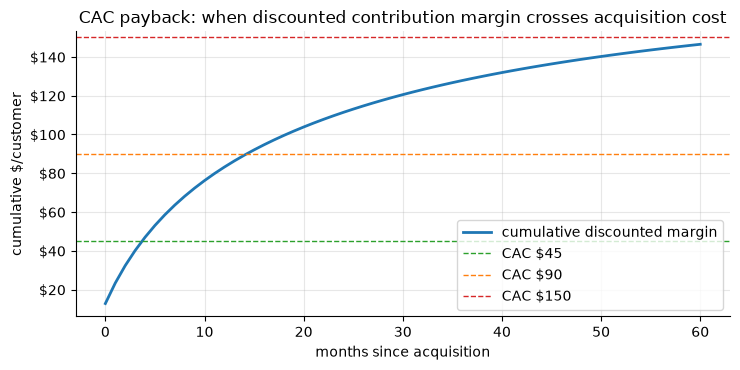

In [3]:
# CAC payback: months until cumulative discounted margin crosses CAC.
cum_dm = np.cumsum(margin_rate * arpu * surv * disc)
for cac in (45, 90, 150):
    crossed = np.argmax(cum_dm >= cac) if cum_dm[-1] >= cac else None
    txt = f"month {crossed}" if crossed is not None else "never within 60m"
    print(f"CAC ${cac:>3}: payback at {txt},  60m disc. LTV:CAC = {cum_dm[-1] / cac:.2f}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(months, cum_dm, lw=2, label="cumulative discounted margin")
for cac, c in zip((45, 90, 150), ("tab:green", "tab:orange", "tab:red")):
    ax.axhline(cac, color=c, ls="--", lw=1, label=f"CAC ${cac}")
ax.set_xlabel("months since acquisition")
ax.set_ylabel("cumulative $/customer")
ax.yaxis.set_major_formatter(usd)
ax.set_title("CAC payback: when discounted contribution margin crosses acquisition cost")
ax.legend(loc="lower right")
plt.show()

The payback chart is the unit-economics conversation in one picture: at CAC \$45 the
customer pays back in under half a year and the rest is profit; at \$150 the *average*
customer never pays back within five years — and note this is the average, computed with
margin and discounting. Do the same math on undiscounted revenue and CAC \$150 looks
comfortably profitable, which is exactly how over-spending on acquisition gets justified
in practice.

One more definitional point for budget allocation: the LTV that matters for spend
decisions is **marginal**, not average — the value of the *next* customer a channel
delivers, which is usually below the channel average (you saturate the good inventory
first), and the *incremental* value net of customers who would have converted anyway
(see [../03_causal_inference/05_uplift_cate.ipynb](../03_causal_inference/05_uplift_cate.ipynb)).
Averages overstate both.

## 2. Empirical cohort LTV from a transaction log

The workhorse in industry: group customers by acquisition month, accumulate contribution
margin per acquired customer as cohorts age, and read LTV off the curves. No model, no
assumptions — but also no answer for young cohorts beyond their observed age, which is
where the trouble starts.

We simulate a 30-month e-commerce transaction log with planted structure we will need
later:

- Customers arrive in monthly cohorts via two channels. **Organic** customers churn
  slowly (mean 8%/month) and order more; **paid** customers churn fast (mean 24%/month)
  and order less. Within channel, churn and frequency are heterogeneous.
- The **paid share of acquisition rises** from 15% to ~70% across cohorts — a channel mix
  shift, the classic silent killer of cohort extrapolation.
- Each customer's underlying churn hazard is *constant* — declining cohort-level churn
  will emerge purely from heterogeneity (section 3 makes that point sharp).

We simulate each customer's **full future** (60 months) as ground truth, then censor at
calendar month 29 to create the analyst's view.

In [4]:
N_COHORTS, OBS_END, FULL_H = 30, 29, 60          # cohorts 0..29, data through month 29
MARGIN_RATE, ORDER_COST = 0.32, 3.0              # margin = 32% of revenue - $3/order

cohort_sizes = 1000 + 60 * np.arange(N_COHORTS)
cohort_ids = np.repeat(np.arange(N_COHORTS), cohort_sizes)
n_cust = cohort_ids.size

paid_share = np.clip(0.15 + 0.02 * np.arange(N_COHORTS), None, 0.70)
is_paid = rng.random(n_cust) < paid_share[cohort_ids]

# churn hazard theta (constant per customer) and monthly order frequency, by channel
theta = np.where(is_paid, rng.beta(1.6, 5.1, n_cust), rng.beta(1.0, 11.5, n_cust))
freq = np.where(is_paid, rng.gamma(2.0, 0.45, n_cust), rng.gamma(2.0, 0.60, n_cust))
aov = np.where(is_paid, rng.gamma(8.0, 6.0, n_cust), rng.gamma(8.0, 7.0, n_cust))

# lifetime in months (geometric, capped at the 60-month horizon we simulate)
lifetime = np.minimum(rng.geometric(theta), FULL_H + 1)

# long table: one row per (customer, age) while alive
cust_idx = np.repeat(np.arange(n_cust), lifetime)
age = np.concatenate([np.arange(L) for L in lifetime])  # noqa: small loop, 28k iters
orders = rng.poisson(freq[cust_idx])
orders[age == 0] += 1                            # acquisition order in month 0
revenue = np.where(orders > 0,
                   orders * aov[cust_idx] * rng.lognormal(-0.045, 0.30, cust_idx.size), 0.0)
margin = MARGIN_RATE * revenue - ORDER_COST * orders

log = pd.DataFrame({
    "cust": cust_idx, "cohort": cohort_ids[cust_idx], "age": age,
    "cal_month": cohort_ids[cust_idx] + age,
    "channel": np.where(is_paid[cust_idx], "paid", "organic"),
    "orders": orders, "revenue": revenue, "margin": margin,
})
log = log[log["orders"] > 0].reset_index(drop=True)
obs = log[log["cal_month"] <= OBS_END]           # what the analyst can see

print(f"{n_cust:,} customers, {log.shape[0]:,} customer-months with orders "
      f"({obs.shape[0]:,} observable by month {OBS_END})")
print(f"paid share of acquisition: cohort 0 = {paid_share[0]:.0%}, "
      f"cohort 29 = {paid_share[-1]:.0%}")

56,100 customers, 511,976 customer-months with orders (251,563 observable by month 29)
paid share of acquisition: cohort 0 = 15%, cohort 29 = 70%


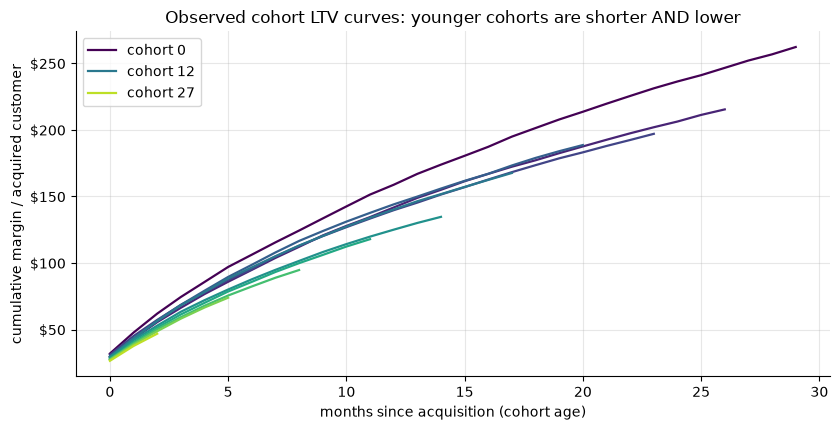

12-month LTV by cohort (observable cohorts only):
cohort
0     158.77
1     151.49
2     151.88
15    125.03
16    123.36
17    122.42
Name: cum margin @ age 12, dtype: float64


In [5]:
# Cumulative margin per acquired customer, by cohort age (the "LTV triangle").
def cum_ltv_curves(df, sizes):
    m = (df.groupby(["cohort", "age"])["margin"].sum().unstack("age")
           .reindex(columns=range(FULL_H + 1)).fillna(0.0))
    m = m.div(pd.Series(sizes, index=m.index), axis=0)
    return m.cumsum(axis=1)

ltv_true = cum_ltv_curves(log, cohort_sizes)              # full-future ground truth
ltv_obs = cum_ltv_curves(obs, cohort_sizes)
for c in ltv_obs.index:                                    # censor: blank unseen ages
    ltv_obs.loc[c, np.arange(FULL_H + 1) > OBS_END - c] = np.nan

fig, ax = plt.subplots(figsize=(8.5, 4.4))
cmap = plt.cm.viridis
for c in range(0, N_COHORTS, 3):
    curve = ltv_obs.loc[c].dropna()
    ax.plot(curve.index, curve.values, color=cmap(c / N_COHORTS), lw=1.6,
            label=f"cohort {c}" if c in (0, 12, 27) else None)
ax.set_xlabel("months since acquisition (cohort age)")
ax.set_ylabel("cumulative margin / acquired customer")
ax.yaxis.set_major_formatter(usd)
ax.set_title("Observed cohort LTV curves: younger cohorts are shorter AND lower")
ax.legend()
plt.show()

m12 = ltv_obs[12].dropna()
print("12-month LTV by cohort (observable cohorts only):")
print(pd.concat([m12.head(3), m12.tail(3)]).round(2).rename("cum margin @ age 12"))

Two things are true at once in this triangle, and separating them is the analyst's job:
young cohorts are **shorter** (censoring — they simply haven't lived long enough) and
**lower** (mix shift — they contain more paid customers, who are genuinely worth less).
Extrapolation methods must fill in the first without being fooled by the second.

### Extrapolating young cohorts, and how it goes wrong

**Method A — curve fitting.** Fit a parametric curve to the young cohort's few observed
points and extrapolate. The problem: several families fit 6 points equally well and
disagree wildly at month 24. Below, a power curve $c(t) = A\,t^{\gamma}$ and a saturating
exponential $c(t) = A\,(1 - e^{-t/\tau})$ both fit cohort 23's observed curve almost
perfectly in-sample — then diverge by tens of percent at month 24. With 6 points you are
choosing the answer when you choose the functional form.

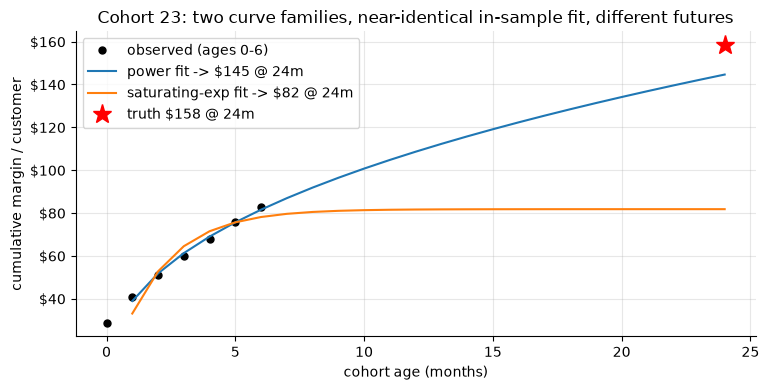

in-sample RMSE: power $1.14, sat-exp $4.36  (both tiny)
24m prediction: power $145 vs sat-exp $82 vs truth $158 -> gap of 40% of truth


In [6]:
young = 23                                       # observed through age 6
yc = ltv_obs.loc[young].dropna()
t_fit, y_fit = yc.index.values[1:].astype(float), yc.values[1:]   # ages 1..6

def power_c(t, A, g):
    return A * t ** g

def satexp_c(t, A, tau):
    return A * (1 - np.exp(-t / tau))

(pA, pg), _ = optimize.curve_fit(power_c, t_fit, y_fit, p0=[20, 0.5])
(sA, stau), _ = optimize.curve_fit(satexp_c, t_fit, y_fit, p0=[60, 5])

t_ext = np.arange(1, 25, dtype=float)
true24 = ltv_true.loc[young, 24]
pred_pow, pred_sat = power_c(24.0, pA, pg), satexp_c(24.0, sA, stau)

fig, ax = plt.subplots(figsize=(7.8, 4.0))
ax.plot(yc.index, yc.values, "ko", ms=5, label="observed (ages 0-6)")
ax.plot(t_ext, power_c(t_ext, pA, pg), "-", color="tab:blue",
        label=f"power fit -> ${pred_pow:.0f} @ 24m")
ax.plot(t_ext, satexp_c(t_ext, sA, stau), "-", color="tab:orange",
        label=f"saturating-exp fit -> ${pred_sat:.0f} @ 24m")
ax.plot(24, true24, "r*", ms=14, label=f"truth ${true24:.0f} @ 24m")
ax.set_xlabel("cohort age (months)")
ax.set_ylabel("cumulative margin / customer")
ax.yaxis.set_major_formatter(usd)
ax.set_title(f"Cohort {young}: two curve families, near-identical in-sample fit, "
             "different futures")
ax.legend()
plt.show()

rmse_p = np.sqrt(np.mean((power_c(t_fit, pA, pg) - y_fit) ** 2))
rmse_s = np.sqrt(np.mean((satexp_c(t_fit, sA, stau) - y_fit) ** 2))
print(f"in-sample RMSE: power ${rmse_p:.2f}, sat-exp ${rmse_s:.2f}  (both tiny)")
print(f"24m prediction: power ${pred_pow:.0f} vs sat-exp ${pred_sat:.0f} "
      f"vs truth ${true24:.0f} -> gap of {abs(pred_pow - pred_sat) / true24:.0%} of truth")

**Method B — borrow the shape of mature cohorts.** More common in practice: compute the
average *shape* of mature cohorts (cumulative margin at age $t$ as a multiple of margin at
age 6), and scale the young cohort's observed age-6 value by it. This fixes the
functional-form problem — the shape comes from data — but imports a new assumption: **the
young cohort ages like the old ones did**. Under a mix shift it doesn't: paid-heavy
cohorts churn faster, so their curves flatten *earlier*, and the mature (organic-heavy)
shape overstates their future. The bias is invisible in-sample; below we quantify it
against ground truth.

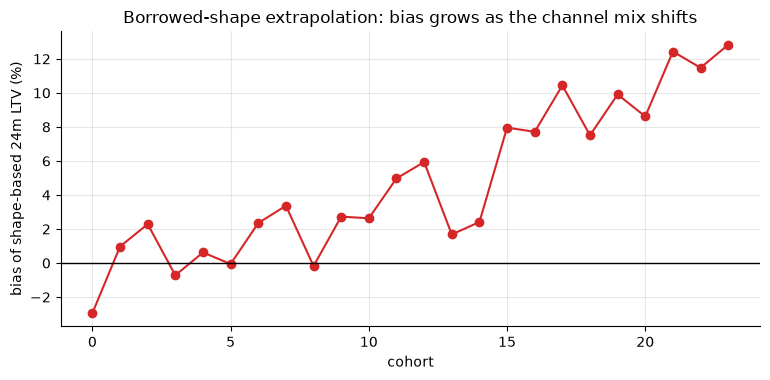

        paid_share  pred_24m  true_24m  bias_%
cohort                                        
0             0.15    229.43    236.38   -2.94
5             0.25    214.16    214.28   -0.06
11            0.37    204.35    194.67    4.97
17            0.49    186.64    168.99   10.44
22            0.59    181.08    162.44   11.48

mean bias, mature cohorts 0-5 (paid share ~20%): +0.0%  <- honest noise level
mean bias, young cohorts 18-23 (paid share ~56%): +10.5%  <- structural overstatement
Mitigation: build shapes WITHIN channel (or segment), then mix-weight; and track mix explicitly.


In [7]:
mature = ltv_obs.loc[0:5]                        # cohorts observed to age >= 24
shape = (mature.div(mature[6], axis=0)).mean(axis=0)   # multiple of age-6 value

pred24_shape = ltv_obs[6].dropna() * shape[24]         # cohorts with age-6 observed
actual24 = ltv_true[24]
cmp24 = pd.DataFrame({
    "paid_share": paid_share[:len(pred24_shape)],
    "pred_24m": pred24_shape,
    "true_24m": actual24.loc[pred24_shape.index],
})
cmp24["bias_%"] = (cmp24["pred_24m"] / cmp24["true_24m"] - 1) * 100

fig, ax = plt.subplots(figsize=(7.8, 3.9))
ax.plot(cmp24.index, cmp24["bias_%"], "o-", color="tab:red")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("cohort")
ax.set_ylabel("bias of shape-based 24m LTV (%)")
ax.set_title("Borrowed-shape extrapolation: bias grows as the channel mix shifts")
plt.show()

print(cmp24.iloc[[0, 5, 11, 17, 22]].round(2))
mature_bias = cmp24.loc[0:5, "bias_%"].mean()
young_bias = cmp24.loc[18:23, "bias_%"].mean()
print(f"\nmean bias, mature cohorts 0-5 (paid share ~{paid_share[0:6].mean():.0%}): "
      f"{mature_bias:+.1f}%  <- honest noise level")
print(f"mean bias, young cohorts 18-23 (paid share ~{paid_share[18:24].mean():.0%}): "
      f"{young_bias:+.1f}%  <- structural overstatement")
print("Mitigation: build shapes WITHIN channel (or segment), then mix-weight; "
      "and track mix explicitly.")

In [8]:
# The fix in one line of extra grouping: per-channel shapes remove most of the bias.
def cum_ltv_by_channel(df):
    m = (df.groupby(["cohort", "channel", "age"])["margin"].sum()
           .unstack("age").reindex(columns=range(FULL_H + 1)).fillna(0.0).cumsum(axis=1))
    n = df.groupby(["cohort", "channel"])["cust"].nunique()
    return m.div(n, axis=0)

ch_obs = cum_ltv_by_channel(obs)
ch_true = cum_ltv_by_channel(log)
bias_rows = []
for c in [11, 17, 22]:
    pred, size_tot = 0.0, 0
    for ch in ("organic", "paid"):
        sh = (ch_obs.loc[(slice(0, 5), ch), :].div(
              ch_obs.loc[(slice(0, 5), ch), 6], axis=0)).mean(axis=0)
        n_ch = obs[(obs["cohort"] == c) & (obs["channel"] == ch)]["cust"].nunique()
        pred += ch_obs.loc[(c, ch), 6] * sh[24] * n_ch
        size_tot += n_ch
    pred /= size_tot
    truth = ltv_true.loc[c, 24]
    bias_rows.append({"cohort": c, "pooled_bias_%": cmp24.loc[c, "bias_%"],
                      "per_channel_bias_%": (pred / truth - 1) * 100})
print(pd.DataFrame(bias_rows).set_index("cohort").round(1))
print("\nSegmenting by the mix-shifting variable turns a structural bias into noise.")

        pooled_bias_%  per_channel_bias_%
cohort                                   
11                5.0                 1.3
17               10.4                 1.9
22               11.5                -1.3

Segmenting by the mix-shifting variable turns a structural bias into noise.


## 3. Contractual LTV: the shifted-Beta-Geometric (sBG) model from scratch

**Contractual** settings (subscriptions, SaaS, insurance) observe churn directly: a
customer either renews or doesn't. The modeling question is the shape of survival, and the
central empirical fact is that **cohort churn rates decline with tenure** almost
everywhere. Two mechanisms can produce that:

1. **Individual-level duration dependence** — each customer really becomes less likely to
   churn as they build habit/switching costs.
2. **Heterogeneity + sorting** — each customer has a *constant* hazard, but hazards
   differ; the high-hazard customers die first, so the surviving pool gets better every
   period.

The sBG model (Fader & Hardie 2007) is the minimal model of mechanism 2: individual churn
probability $\theta \sim \text{Beta}(\alpha, \beta)$, geometric lifetime given $\theta$.
Integrating out $\theta$:

$$P(T = t) = \frac{B(\alpha + 1, \beta + t - 1)}{B(\alpha, \beta)}, \qquad
  S(t) = \frac{B(\alpha, \beta + t)}{B(\alpha, \beta)}$$

with the elegant retention-rate form $r(t) = S(t)/S(t-1) = \frac{\beta + t - 1}{\alpha +
\beta + t - 1} \uparrow 1$: retention *provably* improves with tenure even though no
individual improves. (Distinguishing the two mechanisms needs individual-level covariates
or experiments — see [./02_churn_survival.ipynb](./02_churn_survival.ipynb) for
frailty vs duration-dependence in survival models.)

We simulate a subscription cohort with known $(\alpha, \beta)$, observe **12 renewal
periods**, fit sBG by maximum likelihood on the aggregate retention table (that is all it
needs — a strength worth mentioning in interviews), and project 48 months ahead.

In [9]:
ALPHA_TRUE, BETA_TRUE = 1.2, 6.8                 # E[theta] = 0.15, heterogeneous
N_SUB, OBS_T, PROJ_T = 20_000, 12, 48

theta_sub = rng.beta(ALPHA_TRUE, BETA_TRUE, N_SUB)
life_sub = rng.geometric(theta_sub)              # churns AT end of period life_sub
t_grid = np.arange(0, PROJ_T + 1)
surv_emp_full = np.array([(life_sub > t).mean() for t in t_grid])   # ground truth
deaths = np.array([(life_sub == t).sum() for t in range(1, OBS_T + 1)])
n_alive_end = (life_sub > OBS_T).sum()

def sbg_logS(t, a, b):                           # log S(t)
    return betaln(a, b + t) - betaln(a, b)

def sbg_logpmf(t, a, b):                         # log P(T=t), t >= 1
    return betaln(a + 1, b + t - 1) - betaln(a, b)

def sbg_nll(log_params):
    a, b = np.exp(log_params)
    ts = np.arange(1, OBS_T + 1)
    ll = (deaths * sbg_logpmf(ts, a, b)).sum() + n_alive_end * sbg_logS(OBS_T, a, b)
    return -ll

fit = optimize.minimize(sbg_nll, x0=np.log([1.0, 1.0]), method="Nelder-Mead")
a_hat, b_hat = np.exp(fit.x)
print(f"sBG MLE:   alpha = {a_hat:.3f}, beta = {b_hat:.3f}")
print(f"truth  :   alpha = {ALPHA_TRUE:.3f}, beta = {BETA_TRUE:.3f}")
print(f"mean churn E[theta]: fitted {a_hat / (a_hat + b_hat):.3f}, "
      f"true {ALPHA_TRUE / (ALPHA_TRUE + BETA_TRUE):.3f}")

sBG MLE:   alpha = 1.218, beta = 6.880
truth  :   alpha = 1.200, beta = 6.800
mean churn E[theta]: fitted 0.150, true 0.150


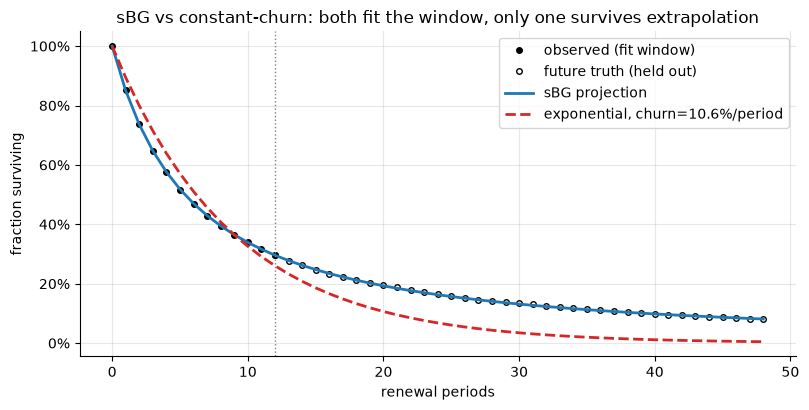

S(48): truth 0.081, sBG 0.081, exponential 0.005


In [10]:
# The competitor: constant-churn (exponential) model.
# Churn estimate = pooled per-period churn among those at risk over the window.
at_risk = np.array([(life_sub >= t).sum() for t in range(1, OBS_T + 1)])
churn_pooled = deaths.sum() / at_risk.sum()
surv_exp = (1 - churn_pooled) ** t_grid
surv_sbg = np.exp(sbg_logS(t_grid, a_hat, b_hat))

fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.plot(t_grid[:OBS_T + 1], surv_emp_full[:OBS_T + 1], "ko", ms=4, label="observed (fit window)")
ax.plot(t_grid[OBS_T:], surv_emp_full[OBS_T:], "o", mfc="none", color="k", ms=4,
        label="future truth (held out)")
ax.plot(t_grid, surv_sbg, "-", color="tab:blue", lw=2, label="sBG projection")
ax.plot(t_grid, surv_exp, "--", color="tab:red", lw=2,
        label=f"exponential, churn={churn_pooled:.1%}/period")
ax.axvline(OBS_T, color="gray", ls=":", lw=1)
ax.set_xlabel("renewal periods")
ax.set_ylabel("fraction surviving")
ax.yaxis.set_major_formatter(pct0)
ax.set_title("sBG vs constant-churn: both fit the window, only one survives extrapolation")
ax.legend()
plt.show()

print(f"S(48): truth {surv_emp_full[48]:.3f}, sBG {surv_sbg[48]:.3f}, "
      f"exponential {surv_exp[48]:.3f}")

In [11]:
# Cohort churn rate by tenure: declining, though every individual's hazard is constant.
cohort_churn = deaths / at_risk
retention_fit = (b_hat + np.arange(1, OBS_T + 1) - 1) / (a_hat + b_hat + np.arange(1, OBS_T + 1) - 1)
tenure_tbl = pd.DataFrame({
    "period": np.arange(1, OBS_T + 1),
    "cohort_churn_rate": cohort_churn,
    "sBG_implied_churn": 1 - retention_fit,
}).set_index("period")
print(tenure_tbl.round(4).T)
print("\nChurn falls from {:.1%} to {:.1%} across 12 periods with zero individual-level "
      "habit formation:\npure sorting on heterogeneous theta.".format(
          cohort_churn[0], cohort_churn[-1]))

period                 1       2       3       4       5       6       7       8       9       10      11      12
cohort_churn_rate  0.1485  0.1354  0.1210  0.1109  0.1017  0.0951  0.0836  0.0822  0.0746  0.0670  0.0707  0.0613
sBG_implied_churn  0.1504  0.1339  0.1206  0.1097  0.1007  0.0930  0.0864  0.0807  0.0756  0.0712  0.0673  0.0638

Churn falls from 14.8% to 6.1% across 12 periods with zero individual-level habit formation:
pure sorting on heterogeneous theta.


### Where `LTV = margin / churn` fails, quantified

The folk formula treats churn as constant: with margin $m$ per period (paid at period
start) and discount rate $d$ per period,
$\text{LTV} = m \sum_{t \ge 0} \left(\frac{1-c}{1+d}\right)^t = m\,\frac{1+d}{c + d}$,
and with $d = 0$ simply $m/c$. Plug in the pooled 12-period churn rate — a perfectly
reasonable-looking estimate — and you get one number. Replace the geometric survival with
the sBG survival (or the truth) and you get a very different one, because when hazards
decline, **the customers who survive the window are precisely the ones with long
futures**. The formula is not "approximately right"; on realistic parameters it is off by
tens of percent, in the *conservative-looking* direction for valuation (it understates
tail value) yet can overstate short-horizon value. There is no salvage: the formula is
only correct when the hazard really is flat.

In [12]:
m_per, d_per = 30.0, 0.01                        # $30 margin/period, 1%/period discount

# extend curves to 600 periods for the infinite-horizon comparison
t_long = np.arange(0, 600)
disc_long = (1 + d_per) ** -t_long.astype(float)
surv_sbg_long = np.exp(sbg_logS(t_long, a_hat, b_hat))
surv_exp_long = (1 - churn_pooled) ** t_long
ltv_naive_closed = m_per * (1 + d_per) / (churn_pooled + d_per)
ltv_sbg = m_per * (surv_sbg_long * disc_long).sum()
ltv_true_mc = m_per * np.mean(
    [((1 + d_per) ** -np.arange(L)).sum() for L in np.minimum(life_sub, 600)])

print(f"naive m/(c+d) style LTV  : ${ltv_naive_closed:7.2f}   (churn = pooled {churn_pooled:.1%})")
print(f"sBG discounted LTV       : ${ltv_sbg:7.2f}")
print(f"ground-truth (simulated) : ${ltv_true_mc:7.2f}")
print(f"\nnaive understates true discounted LTV by "
      f"{(1 - ltv_naive_closed / ltv_true_mc):.0%}; sBG is within "
      f"{abs(ltv_sbg / ltv_true_mc - 1):.1%}")

# and the same failure as a function of which churn estimate you plug in:
for label, c in [("period-1 churn", cohort_churn[0]), ("pooled 12-period", churn_pooled),
                 ("period-12 churn", cohort_churn[-1])]:
    print(f"m*(1+d)/(c+d) with {label:<17} ({c:.1%}) -> ${m_per * (1 + d_per) / (c + d_per):.0f}")
print("\nThe 'one churn number' is a free parameter that moves LTV by 2x - "
      "the formula, not the estimate, is the problem.")

naive m/(c+d) style LTV  : $ 261.09   (churn = pooled 10.6%)


sBG discounted LTV       : $ 382.79
ground-truth (simulated) : $ 384.21

naive understates true discounted LTV by 32%; sBG is within 0.4%
m*(1+d)/(c+d) with period-1 churn    (14.8%) -> $191
m*(1+d)/(c+d) with pooled 12-period  (10.6%) -> $261
m*(1+d)/(c+d) with period-12 churn   (6.1%) -> $425

The 'one churn number' is a free parameter that moves LTV by 2x - the formula, not the estimate, is the problem.


## 4. Non-contractual LTV: BG/NBD + Gamma-Gamma, implemented from scratch

In **non-contractual** settings (retail, e-commerce, marketplaces) churn is *latent*: a
customer who hasn't bought in six months may be gone or just slow. The Fader–Hardie
"buy 'til you die" stack handles this with two independent sub-models:

**BG/NBD (transactions).** While alive, customer $i$ buys in continuous time as a Poisson
process with rate $\lambda_i \sim \text{Gamma}(r, \alpha)$. After *each* purchase they die
with probability $p_i \sim \text{Beta}(a, b)$. Everything is estimated from three summary
statistics per customer — **frequency** $x$ (repeat purchases), **recency** $t_x$ (time of
last repeat purchase), and **age** $T$ — i.e. from an RFM table, not the raw log. The
model's answer to "is a quiet customer dead?" is probabilistic and depends on their own
history: 10 purchases then 8 quiet weeks is damning, 1 purchase then 8 quiet weeks is not.

**Gamma-Gamma (monetary value).** Spend per transaction $z \sim \text{Gamma}(p, \nu_i)$
with $\nu_i \sim \text{Gamma}(q, \gamma)$, assumed **independent of frequency** — an
assumption you must check, because heavy buyers are often also bigger (or smaller)
spenders.

Expected future value over horizon $t$:
$\;E[V_i] = E[Y_i(t) \mid x, t_x, T] \times E[M_i \mid \bar{m}, x] \times \text{margin
rate}$, optionally discounted (Fader–Hardie's DERT). We simulate exactly this generative
process, fit both models by MLE with `scipy` only, and validate on a held-out 26-week
forecast window.

In [13]:
# Simulate one acquisition cohort, 52 weeks of transactions, calibration split at week 26.
R_T, ALPHA_T, A_T, B_T = 0.8, 6.0, 0.7, 2.8      # BG/NBD truth
P_T, Q_T, G_T = 6.0, 4.0, 15.0                   # Gamma-Gamma truth (E[spend]=$30)
N_NC, T_CAL, T_HOLD, MAXK = 3_000, 26.0, 26.0, 80

lam = rng.gamma(R_T, 1 / ALPHA_T, N_NC)          # purchase rate/week while alive
p_die = rng.beta(A_T, B_T, N_NC)
nu = rng.gamma(Q_T, 1 / G_T, N_NC)               # customer spend scale

# transaction k = 1..MAXK after the acquisition purchase at t=0
inter = rng.exponential(1 / lam[:, None], (N_NC, MAXK))
tx_times = np.cumsum(inter, axis=1)
alive_through = rng.random((N_NC, MAXK)) < (1 - p_die)[:, None]  # survives purchase k?
# customer is alive for purchase k if they survived purchases 1..k-1 AND the acquisition
survived_upto = np.concatenate(
    [np.ones((N_NC, 1), bool), np.cumprod(alive_through, axis=1)[:, :-1].astype(bool)], axis=1)
valid = survived_upto & (tx_times <= T_CAL + T_HOLD)

x_cal = ((tx_times <= T_CAL) & valid).sum(axis=1).astype(float)
with np.errstate(invalid="ignore"):
    t_x = np.where(x_cal > 0, np.max(np.where((tx_times <= T_CAL) & valid, tx_times, 0), axis=1), 0.0)
T_age = np.full(N_NC, T_CAL)
x_hold = ((tx_times > T_CAL) & valid).sum(axis=1).astype(float)

# spend per transaction (also for the acquisition purchase at t=0)
spend_cal_sum = np.zeros(N_NC)
n_tx_cal = x_cal + 1                             # incl. acquisition purchase
for i in range(N_NC):                            # 3k iterations, cheap
    k = int(n_tx_cal[i])
    spend_cal_sum[i] = rng.gamma(P_T, 1 / nu[i], k).sum()
mbar = spend_cal_sum / n_tx_cal                  # average observed spend/transaction

rfm = pd.DataFrame({"x": x_cal, "t_x": t_x, "T": T_age, "mbar": mbar, "x_hold": x_hold})
print(rfm.describe().loc[["mean", "std", "50%", "max"]].round(2))
print(f"\nzero repeat purchases in calibration: {(x_cal == 0).mean():.0%} of customers")

          x    t_x     T    mbar  x_hold
mean   2.24  10.69  26.0   29.18    1.41
std    2.94   9.56   0.0   20.70    2.62
50%    1.00   8.99  26.0   23.79    0.00
max   28.00  25.99  26.0  242.95   29.00

zero repeat purchases in calibration: 27% of customers


In [14]:
# BG/NBD log-likelihood (Fader-Hardie 2005 eq. 4), vectorized over customers.
def bgnbd_nll(log_params, x, t_x, T):
    r, alpha, a, b = np.exp(log_params)
    A1 = gammaln(r + x) - gammaln(r) + r * np.log(alpha)
    A2 = gammaln(a + b) + gammaln(b + x) - gammaln(b) - gammaln(a + b + x)
    logD1 = -(r + x) * np.log(alpha + T)                       # still-alive path
    with np.errstate(divide="ignore"):
        logD2 = np.where(x > 0, np.log(a) - np.log(b + np.maximum(x, 1) - 1)
                         - (r + x) * np.log(alpha + t_x), -np.inf)  # died-at-t_x path
    ll = A1 + A2 + logsumexp(np.stack([logD1, logD2]), axis=0)
    return -ll.sum()

fit_bg = optimize.minimize(bgnbd_nll, x0=np.log([1.0, 3.0, 1.0, 3.0]),
                           args=(x_cal, t_x, T_age), method="Nelder-Mead",
                           options={"maxiter": 4000, "xatol": 1e-6, "fatol": 1e-8})
r_h, al_h, a_h, b_h = np.exp(fit_bg.x)
print("BG/NBD MLE vs truth:")
print(pd.DataFrame({"fitted": [r_h, al_h, a_h, b_h],
                    "true": [R_T, ALPHA_T, A_T, B_T]},
                   index=["r", "alpha", "a", "b"]).round(3))

BG/NBD MLE vs truth:
       fitted  true
r       0.772   0.8
alpha   5.897   6.0
a       0.709   0.7
b       3.014   2.8


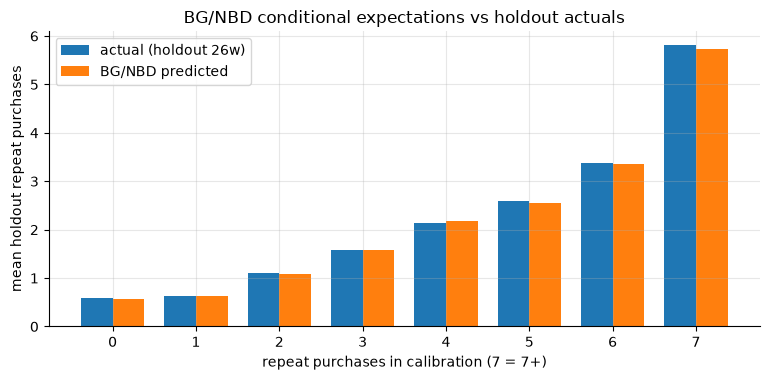

         n  predicted  actual
x_cal                        
0.0    814      0.560   0.592
1.0    827      0.624   0.622
2.0    457      1.076   1.096
3.0    283      1.572   1.572
4.0    203      2.182   2.143
5.0    124      2.555   2.597
6.0     70      3.347   3.371
7.0    222      5.727   5.806

aggregate holdout purchases: actual 4224, predicted 4174 (-1.2%)
corr(pred, actual) across customers: 0.683


In [15]:
# Expected transactions in the next t weeks, conditional on (x, t_x, T)  [FH 2005 eq. 10]
def bgnbd_cond_exp(t, x, t_x, T, r, alpha, a, b):
    h = hyp2f1(r + x, b + x, a + b + x - 1, t / (alpha + T + t))
    num = ((a + b + x - 1) / (a - 1)) * (
        1 - ((alpha + T) / (alpha + T + t)) ** (r + x) * h)
    den = 1 + np.where(x > 0,
                       (a / (b + np.maximum(x, 1) - 1))
                       * ((alpha + T) / (alpha + np.where(x > 0, t_x, 0) + 1e-12)) ** (r + x),
                       0.0)
    return num / den

pred_hold = bgnbd_cond_exp(T_HOLD, x_cal, t_x, T_age, r_h, al_h, a_h, b_h)

# classic validation: conditional expectation by calibration frequency
grp = pd.DataFrame({"x_cal": np.minimum(x_cal, 7), "pred": pred_hold, "actual": x_hold})
by_x = grp.groupby("x_cal").agg(n=("pred", "size"), predicted=("pred", "mean"),
                                actual=("actual", "mean"))

fig, ax = plt.subplots(figsize=(7.8, 3.9))
w = 0.38
ax.bar(by_x.index - w / 2, by_x["actual"], width=w, label="actual (holdout 26w)")
ax.bar(by_x.index + w / 2, by_x["predicted"], width=w, label="BG/NBD predicted")
ax.set_xlabel("repeat purchases in calibration (7 = 7+)")
ax.set_ylabel("mean holdout repeat purchases")
ax.set_title("BG/NBD conditional expectations vs holdout actuals")
ax.legend()
plt.show()

print(by_x.round(3))
print(f"\naggregate holdout purchases: actual {x_hold.sum():.0f}, "
      f"predicted {pred_hold.sum():.0f} ({pred_hold.sum() / x_hold.sum() - 1:+.1%})")
print(f"corr(pred, actual) across customers: {np.corrcoef(pred_hold, x_hold)[0, 1]:.3f}")

Note what the model does with recency: among customers with the *same* frequency, those
with early $t_x$ (long silence) get discounted expectations. That "alive probability"
machinery is why BG/NBD beats any 'average purchases per customer' heuristic, and it came
from an RFM table of 3 numbers per customer. Two honest imperfections worth naming in an
interview: per-customer correlation with holdout is far from 1 (individual purchase
counts are genuinely noisy; the model's job is to rank and to aggregate well), and the
dropout parameters $(a, b)$ are only weakly identified — quite different $(a, b)$ pairs
imply near-identical observable behavior, so judge the fit on predictions, not on
parameter recovery.

### Gamma-Gamma for spend, and the independence check

In [16]:
# Gamma-Gamma MLE on customers with at least one calibration transaction (all, here —
# everyone has the acquisition purchase; n_tx >= 1).
def gg_nll(log_params, n_tx, mbar):
    p, q, g = np.exp(log_params)
    ll = (gammaln(p * n_tx + q) - gammaln(p * n_tx) - gammaln(q)
          + q * np.log(g) + (p * n_tx - 1) * np.log(mbar) + p * n_tx * np.log(n_tx)
          - (p * n_tx + q) * np.log(g + mbar * n_tx))
    return -ll.sum()

fit_gg = optimize.minimize(gg_nll, x0=np.log([2.0, 2.0, 10.0]),
                           args=(n_tx_cal, mbar), method="Nelder-Mead",
                           options={"maxiter": 3000})
p_h, q_h, g_h = np.exp(fit_gg.x)
print("Gamma-Gamma MLE vs truth:")
print(pd.DataFrame({"fitted": [p_h, q_h, g_h], "true": [P_T, Q_T, G_T]},
                   index=["p", "q", "gamma"]).round(3))

# check the independence assumption BEFORE trusting the model:
print(f"\ncorr(frequency, avg spend) = "
      f"{np.corrcoef(n_tx_cal, mbar)[0, 1]:+.3f}  (should be ~0 for Gamma-Gamma)")

# conditional expected spend/transaction: shrink mbar toward the population mean,
# with weight growing in the number of observed transactions
def gg_cond_spend(n_tx, mbar, p, q, g):
    return (g + mbar * n_tx) * p / (p * n_tx + q - 1)

em = gg_cond_spend(n_tx_cal, mbar, p_h, q_h, g_h)
pop_mean = p_h * g_h / (q_h - 1)
show = pd.DataFrame({"n_tx_cal": n_tx_cal, "observed mbar": mbar, "E[M | data]": em})
print(f"\npopulation mean spend/transaction: ${pop_mean:.2f}")
print(show.sort_values("n_tx_cal").iloc[[0, 1500, 2999]].round(2))
print("-> low-count customers get pulled toward the population mean; "
      "heavy buyers keep their own average.")

Gamma-Gamma MLE vs truth:
       fitted  true
p       6.651   6.0
q       4.144   4.0
gamma  13.887  15.0

corr(frequency, avg spend) = +0.004  (should be ~0 for Gamma-Gamma)

population mean spend/transaction: $29.37
      n_tx_cal  observed mbar  E[M | data]
845        1.0          20.60        23.42
1653       2.0          39.43        37.50
2655      29.0          22.35        22.46
-> low-count customers get pulled toward the population mean; heavy buyers keep their own average.


In [17]:
# Put it together: expected 26-week future VALUE per customer, validated in dollars.
future_spend_actual = np.zeros(N_NC)
for i in range(N_NC):
    k_hold = int(x_hold[i])
    if k_hold > 0:
        future_spend_actual[i] = rng.gamma(P_T, 1 / nu[i], k_hold).sum()

pred_value = pred_hold * em * MARGIN_RATE
actual_value = future_spend_actual * MARGIN_RATE

dec = pd.qcut(pred_value, 10, labels=False, duplicates="drop")
val_by_dec = pd.DataFrame({"dec": dec, "pred": pred_value, "actual": actual_value}) \
    .groupby("dec")[["pred", "actual"]].mean()
print("mean 26-week future margin by predicted decile (0=lowest):")
print(val_by_dec.round(2))
print(f"\ntotals: predicted ${pred_value.sum():,.0f} vs actual ${actual_value.sum():,.0f} "
      f"({pred_value.sum() / actual_value.sum() - 1:+.1%})")
top_share = actual_value[dec == 9].sum() / actual_value.sum()
print(f"top predicted decile holds {top_share:.0%} of actual future value")

mean 26-week future margin by predicted decile (0=lowest):
      pred  actual
dec               
0     1.81    1.48
1     3.05    2.84
2     3.82    4.86
3     4.65    4.34
4     5.74    5.05
5     7.36    7.95
6     9.77    8.23
7    14.41   13.89
8    22.35   22.95
9    58.14   64.03

totals: predicted $39,332 vs actual $40,685 (-3.3%)
top predicted decile holds 47% of actual future value


The probabilistic stack earns its keep in three ways a heuristic can't: it separates
*dead* from *quiet* using each customer's own cadence, it shrinks noisy per-customer
spend averages properly (1-purchase customers don't keep their lucky basket), and it
lands aggregate dollars within a few percent of holdout truth with two tiny parametric
models fit on an RFM summary. Its limits are equally important to state:
a single cohortless population, no covariates, no seasonality or marketing effects, and
the Gamma-Gamma independence assumption. When you need covariates, promotions, or
channel effects, you move to the ML approach — next section — and keep BG/NBD as the
benchmark to beat.

## 5. ML approach: predict 12-month future value from early behavior

The industrial pattern for acquisition bidding and CRM targeting: at day ~90 of a
customer's life, predict their **next-12-months margin** from early behavior, and feed
that into bids (value-based bidding), audience tiers, and payback dashboards. Unlike
BG/NBD this handles covariates (channel, device, geo, campaign, product mix) and any
feature engineering you like; the price is that you need labeled history (customers old
enough to have revealed their 12-month value) and honest time-based validation
([../04_ml_tabular/02_leakage_validation.ipynb](../04_ml_tabular/02_leakage_validation.ipynb)).

Setup on our simulated log: features from ages 0–2 (first ~90 days), target = margin over
ages 3–14. Train on cohorts 0–9, test on cohorts 10–14 — a **time-based split**, because
in production you always score cohorts younger than any you trained on, and the mix shift
from section 2 is exactly the kind of drift this split reveals.

train 12,700 customers (cohorts 0-9), test 8,600 (cohorts 10-14)
target skew (test): 38% zeros, skewness 3.1, top 5% of customers hold 33% of all future margin


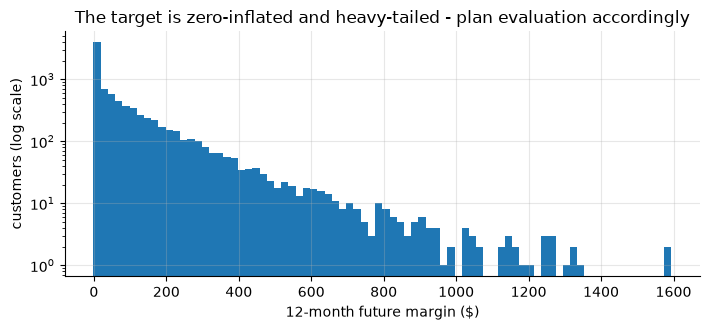

In [18]:
ml_pool = obs[obs["cohort"] <= 14]
feat_w = ml_pool[ml_pool["age"] <= 2]
targ_w = ml_pool[ml_pool["age"].between(3, 14)]

feats = feat_w.groupby("cust").agg(
    orders_90d=("orders", "sum"), revenue_90d=("revenue", "sum"),
    margin_90d=("margin", "sum"), active_months=("age", "nunique"),
    last_order_age=("age", "max"), orders_m0=("orders", lambda s: s.iloc[0]),
)
feats["aov_90d"] = feats["revenue_90d"] / feats["orders_90d"]
target = targ_w.groupby("cust")["margin"].sum()

ml = feats.copy()
ml["cohort"] = cohort_ids[ml.index]
ml["is_paid"] = is_paid[ml.index].astype(int)
ml["y"] = target.reindex(ml.index).fillna(0.0)

train, test = ml[ml["cohort"] <= 9], ml[ml["cohort"] >= 10]
X_cols = ["orders_90d", "revenue_90d", "margin_90d", "active_months",
          "last_order_age", "orders_m0", "aov_90d", "is_paid"]
print(f"train {train.shape[0]:,} customers (cohorts 0-9), "
      f"test {test.shape[0]:,} (cohorts 10-14)")
print(f"target skew (test): {np.mean(test['y'] == 0):.0%} zeros, "
      f"skewness {stats.skew(test['y']):.1f}, "
      f"top 5% of customers hold {test['y'].nlargest(int(0.05 * len(test))).sum() / test['y'].sum():.0%} of all future margin")

fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.hist(test["y"], bins=80)
ax.set_yscale("log")
ax.set_xlabel("12-month future margin ($)")
ax.set_ylabel("customers (log scale)")
ax.set_title("The target is zero-inflated and heavy-tailed - plan evaluation accordingly")
plt.show()

In [19]:
model = lgb.LGBMRegressor(
    n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=40,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, verbose=-1)
model.fit(train[X_cols], train["y"])
pred = model.predict(test[X_cols])

pred_mean = np.full(len(test), train["y"].mean())                 # baseline 1
seg_means = train.groupby(["is_paid", "active_months"])["y"].mean().rename("seg_mean")
pred_seg = (test.merge(seg_means, left_on=["is_paid", "active_months"],
                       right_index=True, how="left")["seg_mean"]
            .fillna(train["y"].mean()).to_numpy())                # baseline 2

def rmse(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2)))

y_te = test["y"].to_numpy()
scores = pd.DataFrame({
    "RMSE": [rmse(y_te, pred_mean), rmse(y_te, pred_seg), rmse(y_te, pred)],
    "spearman": [0.0, stats.spearmanr(pred_seg, y_te).statistic,
                 stats.spearmanr(pred, y_te).statistic],
}, index=["global mean", "segment means", "LightGBM"])
scores["RMSE_vs_mean_%"] = (1 - scores["RMSE"] / scores.loc["global mean", "RMSE"]) * 100
print(scores.round(3))

                  RMSE  spearman  RMSE_vs_mean_%
global mean    157.633     0.000           0.000
segment means  137.463     0.569          12.796
LightGBM       122.574     0.586          22.241


### Why plain RMSE misleads under heavy skew

Look at that table the way a stakeholder would: LightGBM removes barely a fifth of the
global-mean RMSE, and only ~11% beyond a crude two-variable segment lookup. Is the model
barely better than a pivot table? No — RMSE is the wrong lens here, for two structural
reasons worth saying out loud in an interview:

1. **Irreducible noise dominates.** Individual 12-month value is mostly luck (Poisson
   purchase counts, lognormal basket sizes, geometric deaths) around a modest predictable
   component. Even the *oracle* — the true conditional expectation from the simulator —
   has a large RMSE. RMSE mostly measures noise you cannot remove.
2. **RMSE is whale-dominated.** Squared error concentrates on the top 1% of customers,
   where absolute errors are huge for any model; differences in how well you rank the
   other 99% barely register.

But the business use is *allocation*: who gets the high bid, who gets the retention
perk. For that, what matters is **ranking** (value capture by decile, Gini) and **honest
dollar levels by segment** (calibration). Those views make the differences RMSE hides
visible and decision-relevant — including how close each model gets to the oracle
ceiling, which tells you whether more feature work can still pay for itself.

In [20]:
# Oracle RMSE: expected 12-month margin given the customer's LATENT parameters (theta,
# freq, aov) and their true survival status at the end of the feature window - strictly
# more information than any feature-based model can have.
def true_expected_future_margin(idx):
    th, fr, av = theta[idx], freq[idx], aov[idx]
    exp_margin_m = fr * (MARGIN_RATE * av - ORDER_COST)   # E[lognormal noise] = 1 by design
    ages = np.arange(3, 15)
    p_alive = (1 - th[:, None]) ** (ages[None, :] - 2)    # P(active at t | alive through 2)
    ev = (p_alive * exp_margin_m[:, None]).sum(axis=1)
    return np.where(lifetime[idx] > 2, ev, 0.0)           # already dead -> exactly 0

oracle = true_expected_future_margin(test.index.to_numpy())
print(f"RMSE:  global mean {rmse(y_te, pred_mean):.1f}   LightGBM {rmse(y_te, pred):.1f}   "
      f"ORACLE {rmse(y_te, oracle):.1f}")
print("Even the true conditional expectation leaves most of the RMSE on the table: "
      "the gap worth\nfighting over is model-vs-oracle, not model-vs-zero.")

RMSE:  global mean 157.6   LightGBM 122.6   ORACLE 85.1
Even the true conditional expectation leaves most of the RMSE on the table: the gap worth
fighting over is model-vs-oracle, not model-vs-zero.


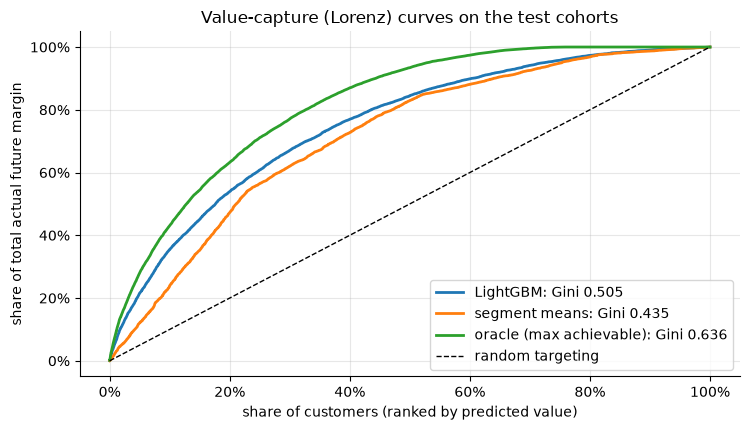

top-20% capture: LightGBM 54% vs segment means 47% (random would capture 20%)
normalized Gini (model / oracle): 0.79


In [21]:
# Value capture: sort customers by prediction, ask what share of total future margin
# the top k% holds. Gini = 2*area between the capture curve and the diagonal.
def capture_curve(y, score):
    order = np.argsort(-score)
    cum_val = np.cumsum(y[order]) / y.sum()
    cum_cust = np.arange(1, len(y) + 1) / len(y)
    return cum_cust, cum_val

def gini(y, score):
    cc, cv = capture_curve(y, score)
    return 2 * (np.trapezoid(cv, cc) - 0.5)

fig, ax = plt.subplots(figsize=(7.6, 4.4))
for name, sc, color in [("LightGBM", pred, "tab:blue"),
                        ("segment means", pred_seg, "tab:orange"),
                        ("oracle (max achievable)", oracle, "tab:green")]:
    cc, cv = capture_curve(y_te, sc)
    ax.plot(cc, cv, color=color, lw=2,
            label=f"{name}: Gini {gini(y_te, sc):.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random targeting")
ax.set_xlabel("share of customers (ranked by predicted value)")
ax.set_ylabel("share of total actual future margin")
ax.xaxis.set_major_formatter(pct0)
ax.yaxis.set_major_formatter(pct0)
ax.set_title("Value-capture (Lorenz) curves on the test cohorts")
ax.legend(loc="lower right")
plt.show()

top2 = y_te[np.argsort(-pred)][:int(0.2 * len(y_te))].sum() / y_te.sum()
top2_seg = y_te[np.argsort(-pred_seg)][:int(0.2 * len(y_te))].sum() / y_te.sum()
print(f"top-20% capture: LightGBM {top2:.0%} vs segment means {top2_seg:.0%} "
      f"(random would capture 20%)")
print(f"normalized Gini (model / oracle): {gini(y_te, pred) / gini(y_te, oracle):.2f}")

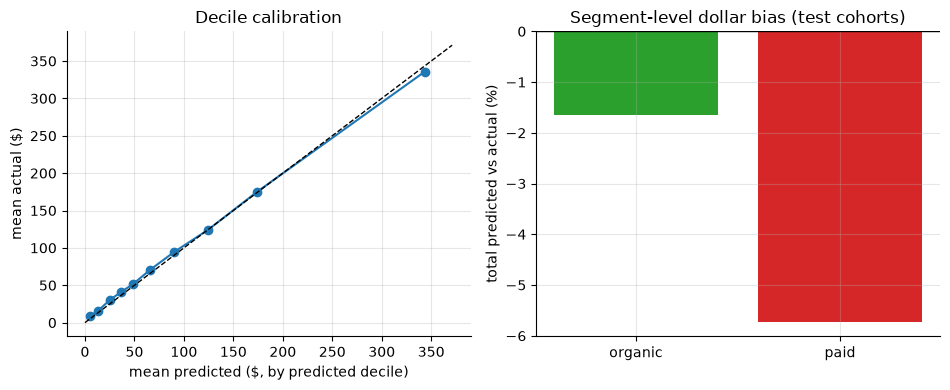

          pred       y
decile                
0         5.58    9.34
1        13.43   15.97
2        25.09   30.32
3        36.03   40.55
4        48.32   51.29
5        66.00   70.82
6        90.00   94.39
7       124.52  124.29
8       174.19  175.23
9       343.67  335.98

segment totals:
             pred         y  bias_%
is_paid                            
organic  682907.5  694319.6    -1.6
paid     113883.4  120803.1    -5.7

overall dollar bias: -2.2% -> recalibrate levels on recent cohorts before spending against them


In [22]:
# Calibration: do predicted dollars match actual dollars where it counts - by decile
# and by segment? (Ranking well but over-predicting levels still burns real budget.)
test_eval = test.assign(pred=pred)
test_eval["decile"] = pd.qcut(test_eval["pred"], 10, labels=False)
cal_dec = test_eval.groupby("decile")[["pred", "y"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0))
axes[0].plot(cal_dec["pred"], cal_dec["y"], "o-")
lim = [0, cal_dec.to_numpy().max() * 1.08]
axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set_xlabel("mean predicted ($, by predicted decile)")
axes[0].set_ylabel("mean actual ($)")
axes[0].set_title("Decile calibration")

seg_cal = test_eval.groupby(test_eval["is_paid"].map({0: "organic", 1: "paid"})) \
    [["pred", "y"]].sum()
seg_cal["bias_%"] = (seg_cal["pred"] / seg_cal["y"] - 1) * 100
axes[1].bar(seg_cal.index, seg_cal["bias_%"], color=["tab:green", "tab:red"])
axes[1].axhline(0, color="k", lw=1)
axes[1].set_ylabel("total predicted vs actual (%)")
axes[1].set_title("Segment-level dollar bias (test cohorts)")
plt.show()

print(cal_dec.round(2))
print("\nsegment totals:")
print(seg_cal.round(1))
print(f"\noverall dollar bias: {test_eval['pred'].sum() / test_eval['y'].sum() - 1:+.1%} "
      "-> recalibrate levels on recent cohorts before spending against them")

Reading the calibration panel like a senior reviewer:

- **Decile calibration** tracks the diagonal through the middle and top of the
  distribution — the dollar scale is broadly usable, not just the ranking. The visible
  miss is the bottom decile (under-predicted in relative terms, small in dollars): the
  zero-inflated floor is where a squared-loss regressor is sloppiest. (Train on
  `log1p(y)` and exponentiate back and you break the dollar scale wholesale — Jensen's
  inequality; exercise 3 quantifies it.)
- **Segment/total bias** is the check that catches silent budget errors: totals run ~2%
  cold overall but ~6% cold on the *paid* segment — and channel-level bias directly
  mis-splits budget between channels even when the overall number looks fine. It is
  invisible in RMSE and Gini. In production this is why LTV models get **recalibrated
  per segment and cohort** (a scalar or isotonic post-fit on recent cohorts) and
  monitored like any other model
  ([../10_ml_in_production/01_drift_monitoring.ipynb](../10_ml_in_production/01_drift_monitoring.ipynb)).
- Alternatives worth naming: a **Tweedie objective** (`objective="tweedie"`) matches the
  zero-inflated continuous target natively; a **two-stage model** (P(any purchase) x
  spend | purchase) mirrors BG/NBD x Gamma-Gamma and gives calibrated components; and
  quantile objectives give you uncertainty bands per customer
  ([../04_ml_tabular/03_evaluation_calibration.ipynb](../04_ml_tabular/03_evaluation_calibration.ipynb)).

## 6. Common errors gallery

Four errors that produce confidently wrong LTV numbers in real organizations. Each one
demonstrated, not just described.

### Error 1 — averaging ratios

"Average LTV:CAC across campaigns" weights every campaign equally, no matter how much
money it burned. The mean of per-campaign ratios can look great while the *portfolio* —
total LTV over total CAC — loses money, because the big-budget campaigns are the bad
ones. Same delta-method territory as ratio metrics in experiments
([../02_ab_testing/05_ratio_metrics_delta_method.ipynb](../02_ab_testing/05_ratio_metrics_delta_method.ipynb)):
a ratio of sums is not a mean of ratios.

In [23]:
camp = pd.DataFrame({
    "campaign": [f"C{i}" for i in range(1, 9)],
    "spend": [2_000, 3_000, 2_500, 1_500, 2_000, 4_000, 3_000, 82_000],
    "ltv_per_$": [4.8, 4.1, 3.9, 5.2, 4.5, 3.6, 4.2, 0.9],   # LTV generated per $ spent
})
camp["ltv_total"] = camp["spend"] * camp["ltv_per_$"]

mean_of_ratios = camp["ltv_per_$"].mean()
ratio_of_sums = camp["ltv_total"].sum() / camp["spend"].sum()
print(camp.to_string(index=False))
print(f"\nmean of per-campaign LTV:CAC : {mean_of_ratios:.2f}  <- what the slide says")
print(f"portfolio LTV / portfolio CAC: {ratio_of_sums:.2f}  <- what the bank account says")
print("One whale campaign (C8) holds 82% of spend at 0.9x. Spend-weight the ratio, "
      "or report dollars.")

campaign  spend  ltv_per_$  ltv_total
      C1   2000        4.8     9600.0
      C2   3000        4.1    12300.0
      C3   2500        3.9     9750.0
      C4   1500        5.2     7800.0
      C5   2000        4.5     9000.0
      C6   4000        3.6    14400.0
      C7   3000        4.2    12600.0
      C8  82000        0.9    73800.0

mean of per-campaign LTV:CAC : 3.90  <- what the slide says
portfolio LTV / portfolio CAC: 1.49  <- what the bank account says
One whale campaign (C8) holds 82% of spend at 0.9x. Spend-weight the ratio, or report dollars.


### Error 2 — survivorship in "average customer lifetime"

The folk chain `avg lifetime = observed average x`, `LTV = margin x avg lifetime` breaks
twice. Measuring average lifetime **among customers who already churned** truncates every
long-lived customer out of the sample (they haven't churned yet) — a huge underestimate
early in a product's life. Measuring **average tenure of the current active base** is
biased the other way as the base matures, and is not a "lifetime" at all. Using the
subscription cohort from section 3, observed at month 12:

In [24]:
churned_by_12 = life_sub[life_sub <= OBS_T]
active_at_12_tenure = np.full((life_sub > OBS_T).sum(), OBS_T)   # tenure so far = 12
true_mean_life = life_sub.mean()

est_churned_only = churned_by_12.mean()
print(f"true mean lifetime (simulated to completion)   : {true_mean_life:6.1f} periods")
print(f"'avg lifetime' from churned customers at t=12  : {est_churned_only:6.1f} periods "
      f"({est_churned_only / true_mean_life - 1:+.0%})")
print(f"LTV via margin x avg-lifetime, churned-only    : "
      f"${m_per * est_churned_only:,.0f} vs true undiscounted ${m_per * true_mean_life:,.0f}")
print("\nThe customers still alive at t=12 are exactly the ones with long lifetimes -\n"
      "dropping them is survivorship bias in reverse. The censoring-aware answer is a\n"
      "survival/sBG model (section 3), which uses the still-alive customers as censored\n"
      "observations instead of discarding them.")

true mean lifetime (simulated to completion)   :   29.4 periods
'avg lifetime' from churned customers at t=12  :    4.4 periods (-85%)
LTV via margin x avg-lifetime, churned-only    : $131 vs true undiscounted $881

The customers still alive at t=12 are exactly the ones with long lifetimes -
dropping them is survivorship bias in reverse. The censoring-aware answer is a
survival/sBG model (section 3), which uses the still-alive customers as censored
observations instead of discarding them.


### Error 3 — ignoring margin and discounting

Section 1 already priced this: on the same customer stream, undiscounted *revenue* LTV at
a long horizon vs discounted *margin* LTV at a decision horizon differ by 4x+. The
subtler version inside margin itself: using **gross margin** (COGS only) instead of
**contribution margin** (COGS + shipping + payment + variable support + returns)
flatters every unit-economics number by the same factor everywhere, so nothing looks
wrong until the cash doesn't appear.

In [25]:
gross_rate, contrib_rate = 0.55, 0.32
ltv_gross = ltv_defs.loc[36, "margin LTV"] / margin_rate * gross_rate
ltv_contrib_disc = ltv_defs.loc[36, "disc. margin LTV"]
print(f"36m LTV with gross margin, no discounting : ${ltv_gross:6.0f}")
print(f"36m LTV with contribution margin + 12%/yr : ${ltv_contrib_disc:6.0f}")
print(f"overstatement factor: {ltv_gross / ltv_contrib_disc:.1f}x")
print(f"\nAt CAC $90: the first says LTV:CAC = {ltv_gross / 90:.1f} ('scale up!'), "
      f"the second {ltv_contrib_disc / 90:.1f} ('barely viable').")

36m LTV with gross margin, no discounting : $   241
36m LTV with contribution margin + 12%/yr : $   127
overstatement factor: 1.9x

At CAC $90: the first says LTV:CAC = 2.7 ('scale up!'), the second 1.4 ('barely viable').


### Error 4 — reporting LTV without uncertainty

A cohort LTV is a *mean of a heavy-tailed distribution* estimated from a finite cohort —
it deserves an interval, and the interval is wider than intuition suggests because
whales dominate the sum. Bootstrap a single cohort's 24-month LTV
(resampling customers, per
[../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb)):

cohort 5 (1300 customers), 24m LTV: $214.28, 95% bootstrap CI [$198.82, $230.99]  (± 8%)
top 1% of customers hold 8% of cohort value; dropping the top 10 customers moves LTV to $201.36 (-6.0%)

Decisions keyed to a threshold (e.g. 'LTV must exceed 3x CAC') need the interval.
Two CACs a few dollars apart, both 'passing' on the point estimate:
  CAC $67: point LTV/CAC = 3.20, P(true LTV < 3 x CAC) ~= 5%
  CAC $71: point LTV/CAC = 3.02, P(true LTV < 3 x CAC) ~= 45%


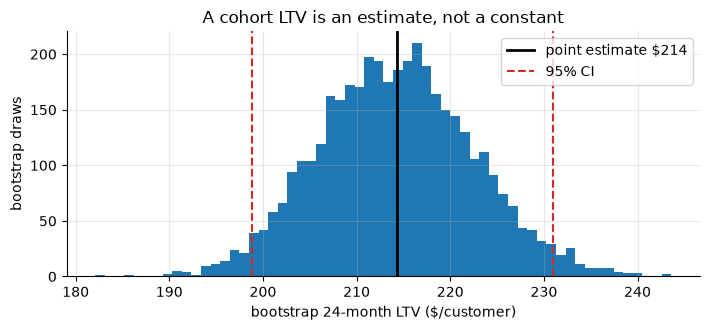

In [26]:
c5 = log[(log["cohort"] == 5) & (log["age"] <= 24)]
per_cust = c5.groupby("cust")["margin"].sum() \
    .reindex(np.flatnonzero(cohort_ids == 5), fill_value=0.0).to_numpy()
n5 = per_cust.size

boot_idx = rng.integers(0, n5, (4000, n5))
boot_ltv = per_cust[boot_idx].mean(axis=1)
lo_b, hi_b = np.percentile(boot_ltv, [2.5, 97.5])
point = per_cust.mean()

top1_share = np.sort(per_cust)[-int(0.01 * n5):].sum() / per_cust.sum()
no_top10 = np.sort(per_cust)[:-10].mean()
print(f"cohort 5 ({n5} customers), 24m LTV: ${point:.2f}, "
      f"95% bootstrap CI [${lo_b:.2f}, ${hi_b:.2f}]  "
      f"(± {100 * (hi_b - lo_b) / 2 / point:.0f}%)")
print(f"top 1% of customers hold {top1_share:.0%} of cohort value; "
      f"dropping the top 10 customers moves LTV to ${no_top10:.2f} "
      f"({no_top10 / point - 1:+.1%})")
print("\nDecisions keyed to a threshold (e.g. 'LTV must exceed 3x CAC') need the interval.")
print("Two CACs a few dollars apart, both 'passing' on the point estimate:")
for cac5 in (round(point / 3 * 0.94), round(point / 3 * 0.99)):
    print(f"  CAC ${cac5}: point LTV/CAC = {point / cac5:.2f}, "
          f"P(true LTV < 3 x CAC) ~= {np.mean(boot_ltv < 3 * cac5):.0%}")

fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.hist(boot_ltv, bins=60)
ax.axvline(point, color="k", lw=2, label=f"point estimate ${point:.0f}")
ax.axvline(lo_b, color="tab:red", ls="--", lw=1.5, label="95% CI")
ax.axvline(hi_b, color="tab:red", ls="--", lw=1.5)
ax.set_xlabel("bootstrap 24-month LTV ($/customer)")
ax.set_ylabel("bootstrap draws")
ax.set_title("A cohort LTV is an estimate, not a constant")
ax.legend()
plt.show()

## 7. Interview corner

**Q1. "How would you compute LTV for our business?"**
Strong answer is a decision tree, asked out loud: (1) *Contractual or non-contractual?*
— determines whether churn is observed (sBG/survival) or latent (BG/NBD-family, ML).
(2) *What decision does it feed?* — finance valuation wants long-horizon discounted
margin with uncertainty; bidding wants per-customer 12-month predictions refreshed daily;
a payback dashboard wants cohort curves and nothing fancier. (3) *How much history?* —
under ~a year, you're extrapolating; say so and bound it. Then the concrete plan:
empirical cohort curves by segment first (they're the audit trail), a probabilistic or ML
model on top, validated on held-out cohorts in time, reported as margin-based, discounted,
with a horizon and an interval. Naming the mix-shift trap when extrapolating young
cohorts is what makes the answer senior.

**Q2. "Finance wants ONE LTV number. What do you push back on?"**
Not on having a headline number — finance legitimately needs one for planning. Push back
on ambiguity: (1) pin the definition (contribution margin, discount rate, horizon) in
writing; (2) one number hides *mix* — new-customer LTV ≠ average-base LTV, and channel
mix shifts move the blend without anything improving; (3) one number hides *uncertainty*
— attach the bootstrap interval, since a threshold decision (LTV > 3x CAC) can flip
within the CI; (4) marginal vs average — the budget decision needs the marginal
customer's LTV. Deliverable: a headline number *plus* the definition, a by-segment table,
and the interval. "One number, footnoted, refreshed monthly" is the compromise that works.

**Q3. "Our LTV/CAC is 3. Good or bad?"**
Interrogate the numerator, denominator, and clock before answering. Numerator: revenue or
margin? discounted? what horizon — a 5-year undiscounted revenue LTV at 3x CAC is likely
*losing* money (section 1 showed 4x+ definitional spread). Denominator: blended CAC or
marginal? paid-only or including organic (which flatters it)? incremental or
last-click-attributed? Clock: payback period — 3x recovered in 6 months vs 30 months are
different businesses; cash constraints bind on payback, not on the ratio. Then context:
the "3x" SaaS heuristic assumes margin-based, discounted, with sane payback; growth stage
and capital cost move the bar. And the composition question: is 3 an average propped up
by an aging high-LTV base while new cohorts run at 1.5?

**Q4. "Contractual vs non-contractual — what actually changes in the modeling?"**
Observability of death. Contractual: churn is an observed event; model the hazard
(sBG for heterogeneity, survival regression for covariates — see
[./02_churn_survival.ipynb](./02_churn_survival.ipynb)); LTV = margin x discounted
expected survival. Non-contractual: death is latent — silence is data, not a label;
models must jointly explain frequency and recency (BG/NBD's P(alive) machinery), and
monetary value is a separate submodel (Gamma-Gamma) with an independence assumption you
check. Practical consequences: contractual LTV can be audited against renewal books;
non-contractual LTV should be validated on a held-out *time window*, and "churn rate"
doesn't exist without defining an inactivity window.

**Q5. "When is LTV = margin/churn acceptable?"**
When hazard is genuinely flat over the horizon that matters and you discount: the honest
version is $m(1+d)/(c+d)$. Acceptable for a quick sanity check on a mature contractual
base with stable per-period churn measured on that base. Unacceptable for young cohorts
or anywhere cohort churn declines with tenure — section 3 showed the pooled-churn version
understating true discounted LTV by ~30% on realistic heterogeneity, and the answer
swinging 2x depending on *which* churn estimate you plug in. If someone hands you an
LTV from this formula, ask "which churn rate, measured on whom, over what window?"

**Q6. "How do you validate an LTV model?"**
Backtest in time: train on data through month $t$, predict cohorts' next-12-month value,
compare against what actually happened — at three resolutions: aggregate dollars (bias),
decile/Lorenz capture (ranking), and segment-level calibration (where the dollars sit).
Track stability of the numbers across successive cohorts — an LTV that jumps 20% between
refreshes is a process problem even if each estimate looked "validated". For probabilistic
models, also check assumptions directly (frequency-spend independence for Gamma-Gamma;
cohort-invariance for sBG pooling).

**Q7. "New product, 3 months of data. LTV?"**
Say the true thing first: any 3-year LTV from 3 months of data is an assumption wearing a
number. Then be useful: give the observed 90-day margin per customer (fact), a range of
12-month projections under mature-product retention shapes from comparable products
(assumption, labeled), and the *leading indicators* that will tighten it fastest (D30/D60
repeat rate vs comparables). Commit to a refresh cadence as cohorts age. This is the
question where saying "confidence interval" without also saying "the interval comes from
model choice, not sampling noise" costs you points.

## 8. Key takeaways

- "LTV" is underdetermined until you fix value basis (contribution margin), discounting,
  horizon, and expected-vs-realized. The same customers supported an almost-7x spread of
  defensible "LTV"s — align definitions before debating models.
- LTV excludes CAC; CAC enters via LTV:CAC and **payback time**, and budget decisions run
  on *marginal, incremental* LTV, not averages.
- Empirical cohort curves are the audit trail. Extrapolating young cohorts fails two
  ways: functional form (many curves fit 6 points; they disagree at month 24) and mix
  shift (borrowed shapes assume young cohorts age like old ones). Segment before you
  extrapolate.
- Cohort churn declining with tenure needs **no individual habit formation** — sorting on
  heterogeneous hazards produces it mechanically (sBG). Consequently `margin/churn` has
  no right churn rate to plug in; it was off ~30% here with a 2x swing across plausible
  choices.
- sBG fits aggregate retention tables (two parameters, no individual data) and
  extrapolates far better than exponential decay; discount the projected survival for
  contractual LTV.
- Non-contractual death is latent: BG/NBD turns frequency + recency into expected future
  transactions and P(alive); Gamma-Gamma shrinks noisy spend averages — after checking
  spend-frequency independence. Both fit from an RFM summary with `scipy` alone.
- For ML LTV under heavy skew, RMSE is nearly uninformative (noise- and
  whale-dominated); evaluate ranking (decile capture, Gini vs an oracle ceiling) and
  dollar calibration by segment, with time-based splits and per-cohort recalibration.
- Never average LTV:CAC ratios across campaigns; weight by spend or report dollars.
- "Average lifetime of churned customers" is survivorship bias — censoring-aware models
  exist precisely to use the still-alive customers.
- Report LTV with an interval: cohort LTV is the mean of a heavy-tailed distribution, and
  threshold decisions can flip inside the CI.

## 9. Exercises

**Exercise 1 — sBG window sensitivity.** Refit the sBG model of section 3 using only the
first **6** observed periods. Compare fitted $(\alpha, \beta)$, projected $S(48)$, and
discounted LTV against the 12-period fit and the truth. What does the result say about
quoting infinite-horizon LTV from young contractual products?

**Exercise 2 — channel payback and budget allocation.** Using the section-2 transaction
log (observed data only, cohorts 0–5 to avoid censoring), build cumulative **discounted**
margin curves per acquired customer *by channel* (12%/yr as in section 1). With CAC of
\$15 (organic) and \$60 (paid): compute payback month and 24-month discounted LTV:CAC per
channel. Which channel gets the marginal dollar, and what would change your answer?

**Exercise 3 — the log-target trap.** Retrain the section-5 LightGBM on
`log1p(y)` and back-transform with `expm1`. Compare Gini and *total predicted dollars*
vs the raw-target model. Explain the direction of the bias (Jensen's inequality) and why
ranking barely changes while dollar calibration breaks.

In [27]:
# --- Solution 1: sBG fit on a 6-period window ---
OBS_T6 = 6
deaths6 = deaths[:OBS_T6]
n_alive6 = (life_sub > OBS_T6).sum()

def sbg_nll6(log_params):
    a, b = np.exp(log_params)
    ts = np.arange(1, OBS_T6 + 1)
    return -((deaths6 * sbg_logpmf(ts, a, b)).sum() + n_alive6 * sbg_logS(OBS_T6, a, b))

a6, b6 = np.exp(optimize.minimize(sbg_nll6, np.log([1.0, 1.0]), method="Nelder-Mead").x)
surv6_long = np.exp(sbg_logS(t_long, a6, b6))
ltv6 = m_per * (surv6_long * disc_long).sum()
cmp1 = pd.DataFrame({
    "alpha": [ALPHA_TRUE, a_hat, a6], "beta": [BETA_TRUE, b_hat, b6],
    "S(48)": [surv_emp_full[48], surv_sbg[48], np.exp(sbg_logS(48, a6, b6))],
    "disc LTV": [ltv_true_mc, ltv_sbg, ltv6],
}, index=["truth", "fit on 12 periods", "fit on 6 periods"])
print(cmp1.round(3))
print("\nSix periods still beat the naive formula, but tail quantities (S(48), "
      "infinite-horizon LTV)\nmove noticeably with the window: quote finite-horizon LTV "
      "while cohorts are young, and\nrefresh the fit as data accrues.")

                   alpha   beta  S(48)  disc LTV
truth              1.200  6.800  0.081   384.212
fit on 12 periods  1.218  6.880  0.081   382.793
fit on 6 periods   1.301  7.419  0.075   369.202

Six periods still beat the naive formula, but tail quantities (S(48), infinite-horizon LTV)
move noticeably with the window: quote finite-horizon LTV while cohorts are young, and
refresh the fit as data accrues.


 organic: 24m disc LTV $234.66, CAC $15, LTV:CAC 15.64, payback month 0
    paid: 24m disc LTV $ 77.47, CAC $60, LTV:CAC 1.29, payback month 8


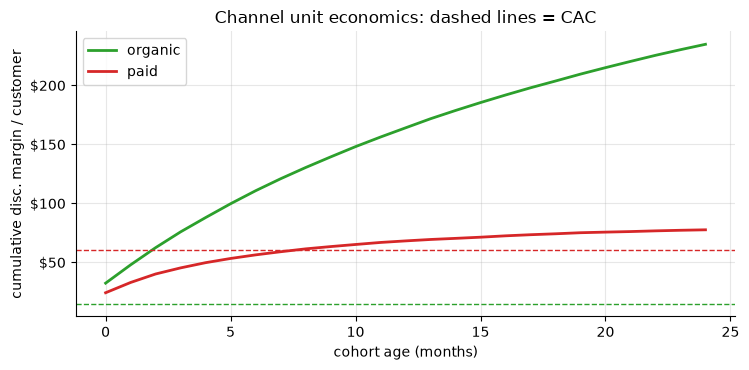


Organic dominates on ratio AND payback -> marginal dollar goes there IF organic spend is
actually scalable (usually it saturates) and IF these are incremental customers (paid ads
partly harvest people who would have arrived organically - see 03_causal_inference/).
Average LTV:CAC by channel is where the analysis starts, not where the decision ends.


In [28]:
# --- Solution 2: channel-level discounted payback ---
c05 = obs[obs["cohort"] <= 5].copy()
disc_age = disc_m ** -c05["age"].to_numpy()
c05["disc_margin"] = c05["margin"] * disc_age
n_by_ch = c05.groupby("channel")["cust"].nunique()

cum_ch = (c05.groupby(["channel", "age"])["disc_margin"].sum().unstack("age")
          .reindex(columns=range(25)).fillna(0.0).cumsum(axis=1).div(n_by_ch, axis=0))
cac_ch = pd.Series({"organic": 15.0, "paid": 60.0})

for ch in ("organic", "paid"):
    curve = cum_ch.loc[ch]
    pb = next((int(a) for a in curve.index if curve[a] >= cac_ch[ch]), None)
    print(f"{ch:>8}: 24m disc LTV ${curve[24]:6.2f}, CAC ${cac_ch[ch]:.0f}, "
          f"LTV:CAC {curve[24] / cac_ch[ch]:4.2f}, payback "
          f"{'month ' + str(pb) if pb is not None else 'beyond 24m'}")

fig, ax = plt.subplots(figsize=(7.6, 3.8))
for ch, color in [("organic", "tab:green"), ("paid", "tab:red")]:
    ax.plot(cum_ch.columns, cum_ch.loc[ch], color=color, lw=2, label=ch)
    ax.axhline(cac_ch[ch], color=color, ls="--", lw=1)
ax.set_xlabel("cohort age (months)")
ax.set_ylabel("cumulative disc. margin / customer")
ax.yaxis.set_major_formatter(usd)
ax.set_title("Channel unit economics: dashed lines = CAC")
ax.legend()
plt.show()

print("\nOrganic dominates on ratio AND payback -> marginal dollar goes there IF organic "
      "spend is\nactually scalable (usually it saturates) and IF these are incremental "
      "customers (paid ads\npartly harvest people who would have arrived organically - "
      "see 03_causal_inference/).\nAverage LTV:CAC by channel is where the analysis "
      "starts, not where the decision ends.")

In [29]:
# --- Solution 3: log-target model vs raw-target model ---
model_log = lgb.LGBMRegressor(
    n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=40,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, verbose=-1)
model_log.fit(train[X_cols], np.log1p(train["y"].clip(lower=0)))  # a handful of slightly
# negative margins (money-losing orders) would break log1p; clip them for the log model
pred_log = np.expm1(model_log.predict(test[X_cols]))

cmp3 = pd.DataFrame({
    "Gini": [gini(y_te, pred), gini(y_te, pred_log)],
    "total pred $": [pred.sum(), pred_log.sum()],
    "total actual $": [y_te.sum()] * 2,
}, index=["raw target", "log1p target"])
cmp3["dollar bias %"] = (cmp3["total pred $"] / cmp3["total actual $"] - 1) * 100
print(cmp3.round(3))
print(f"\nRanking barely moves (Gini {gini(y_te, pred_log):.3f} vs {gini(y_te, pred):.3f}) "
      "- near-monotone transform, same trees.\nDollars are biased low: the model predicts "
      "E[log y]; expm1(E[log y]) < E[y] for a skewed\ntarget (Jensen). Fixes: predict raw "
      "dollars, use a Tweedie objective, or apply a smearing/\ncalibration correction "
      "after back-transforming.")

               Gini  total pred $  total actual $  dollar bias %
raw target    0.505    796790.918       815122.74         -2.249
log1p target  0.490    357433.666       815122.74        -56.150

Ranking barely moves (Gini 0.490 vs 0.505) - near-monotone transform, same trees.
Dollars are biased low: the model predicts E[log y]; expm1(E[log y]) < E[y] for a skewed
target (Jensen). Fixes: predict raw dollars, use a Tweedie objective, or apply a smearing/
calibration correction after back-transforming.
